In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output
import time

In [2]:
class Robot:
    def __init__(self):
        self.x = 0
        self.y = 0
        self.bearing = 0
        self.xWalls = []
        self.yWalls = []

    def distanceSensor(self):
        #this should read from the robot, here it is a math function
        infront = ((self.x+0.5*np.cos(np.radians(self.bearing)))**2 \
                    + (self.y+0.5*np.sin(np.radians(self.bearing)))**2)**0.5>5
        if infront:
            distance =  np.random.rand()*0.5
            self.xWalls.append(self.x+distance*np.cos(np.radians(self.bearing)))
            self.yWalls.append(self.y+distance*np.sin(np.radians(self.bearing)))
            return np.random.rand()*0.5
            
        else:
            return 0

    def turn(self,angle):
        self.bearing += angle
        self.bearing = self.bearing%360

    def move(self,distance):
        self.x += distance*np.cos(np.radians(self.bearing))
        self.y += distance*np.sin(np.radians(self.bearing))    

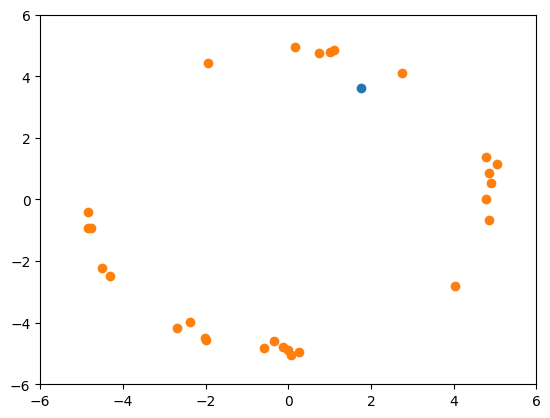

In [3]:
distance = 0.1
robot = Robot()
for n in range(1000):
    if robot.distanceSensor() == 0:
        robot.move(distance)
    else:
        angle = 360*np.random.rand()
        robot.turn(angle)
    clear_output(wait=True)
    plt.xlim(-6, 6)
    plt.ylim(-6, 6)
    plt.scatter([robot.x],[robot.y])
    plt.scatter(robot.xWalls,robot.yWalls)
    plt.show()
    time.sleep(0.1)
    